## Data Preprocessing with Scanpy

In [31]:
# Core scverse libraries
from __future__ import annotations

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc
import math
import os

In [32]:
# Set verbosity to see more log output
sc.settings.verbosity = 4

### Reading in Data from bladder-10x_P4_3 folder into an AnnData object

In [33]:
# Load data from 10X Genomics format directory using scanpys read_10x_mtx function


# sc.read_10x_mtx("droplet/Bladder-10X_P4_3"),
#     sc.read_10x_mtx("droplet/Bladder-10X_P4_4"),
#     sc.read_10x_mtx("droplet/Bladder-10X_P7_7"),
#     sc.read_10x_mtx("droplet/Heart-10X_P7_4"),
#     sc.read_10x_mtx("droplet/Kidney-10X_P4_5"),
#     sc.read_10x_mtx("droplet/Kidney-10X_P4_6"),
#     sc.read_10x_mtx("droplet/Kidney-10X_P7_5"),
#     sc.read_10x_mtx("droplet/Liver-10X_P4_2"),
#     sc.read_10x_mtx("droplet/Liver-10X_P7_0"),
#     sc.read_10x_mtx("droplet/Liver-10X_P7_1"),
#     sc.read_10x_mtx("droplet/Lung-10X_P7_8"),
#     sc.read_10x_mtx("droplet/Lung-10X_P7_9"),
#     sc.read_10x_mtx("droplet/Lung-10X_P8_12"),
#     sc.read_10x_mtx("droplet/Lung-10X_P8_13"),
#     sc.read_10x_mtx("droplet/Mammary-10X_P7_12"),
#     sc.read_10x_mtx("droplet/Mammary-10X_P7_13"),
#     sc.read_10x_mtx("droplet/Marrow-10X_P7_2"),
#     sc.read_10x_mtx("droplet/Marrow-10X_P7_3"),
#     sc.read_10x_mtx("droplet/Muscle-10X_P7_14"),
#     sc.read_10x_mtx("droplet/Muscle-10X_P7_15"),
#     sc.read_10x_mtx("droplet/Spleen-10X_P4_7"),
#     sc.read_10x_mtx("droplet/Spleen-10X_P7_6"),
#     sc.read_10x_mtx("droplet/Thymus-10X_P7_11"),
#     sc.read_10x_mtx("droplet/Tongue-10X_P4_0"),
#     sc.read_10x_mtx("droplet/Tongue-10X_P4_1"),
#     sc.read_10x_mtx("droplet/Tongue-10X_P7_10"),
#     sc.read_10x_mtx("droplet/Trachea-10X_P8_14"),
#     sc.read_10x_mtx("droplet/Trachea-10X_P8_15")

# checking how visualizations look when bladder_droplet_annotations.csv used for cell type labels instead of annotations_droplet.csv

tiss = ad.concat([
    sc.read_10x_mtx("../droplet/Bladder-10X_P4_3"),
    sc.read_10x_mtx("../droplet/Bladder-10X_P4_4"),
    sc.read_10x_mtx("../droplet/Bladder-10X_P7_7"),
])

tiss.obs_names_make_unique()

tiss.obs

    reading ../droplet/Bladder-10X_P4_3/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
    reading ../droplet/Bladder-10X_P4_4/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.
    reading ../droplet/Bladder-10X_P7_7/matrix.mtx
--> This might be very slow. Consider passing `cache=True`, which enables much faster reading from a cache file.


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/anndata/_core/anndata.py:1792: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


""
AAAGTAGAGATGCCAG-1
AACCGCGTCCAACCAA-1
AACTCCCGTCGGGTCT-1
AACTCTTAGTTGCAGG-1
AACTCTTTCATAACCG-1
...
TTGTAGGTCATGTAGC-1
TTTACTGGTGTTGAGG-1
TTTCCTCCATACCATG-1
TTTGTCAGTTACCGAT-1


In [34]:
tiss.obs

""
AAAGTAGAGATGCCAG-1
AACCGCGTCCAACCAA-1
AACTCCCGTCGGGTCT-1
AACTCTTAGTTGCAGG-1
AACTCTTTCATAACCG-1
...
TTGTAGGTCATGTAGC-1
TTTACTGGTGTTGAGG-1
TTTCCTCCATACCATG-1
TTTGTCAGTTACCGAT-1


### Quality Control using Organ Annotation Vignette that described quality control steps done in the study 
https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-018-0590-4/MediaObjects/41586_2018_590_MOESM4_ESM.pdf

In [35]:
sc.pp.filter_cells(tiss, min_genes=500)
sc.pp.filter_cells(tiss, min_counts=1000)

tiss.obs

,n_genes,n_counts
AAAGTAGAGATGCCAG-1,2853,10291.0
AACCGCGTCCAACCAA-1,4194,17520.0
AACTCCCGTCGGGTCT-1,3347,12944.0
AACTCTTAGTTGCAGG-1,3851,19594.0
AACTCTTTCATAACCG-1,3809,14594.0
...,...,...
TTGTAGGTCATGTAGC-1,4296,22993.0
TTTACTGGTGTTGAGG-1,3005,8753.0
TTTCCTCCATACCATG-1,3778,14665.0
TTTGTCAGTTACCGAT-1,4786,30363.0


## Normalization

In [36]:
# Normalizing to median total counts
sc.pp.normalize_total(tiss, target_sum=1e4)

# Logarithmize the data
sc.pp.log1p(tiss)

# Scale (center to 0, unit variance)
sc.pp.scale(tiss)


normalizing counts per cell
    finished (0:00:00)


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/functools.py:912: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


## Feature Selection
By including only the most informative genes. The genes that vary the most in the data.

In [37]:
sc.pp.highly_variable_genes(tiss, flavor="seurat", max_mean=math.inf, min_disp=0.5)

extracting highly variable genes
    finished (0:00:00)
--> added
    'highly_variable', boolean vector (adata.var)
    'means', float vector (adata.var)
    'dispersions', float vector (adata.var)
    'dispersions_norm', float vector (adata.var)


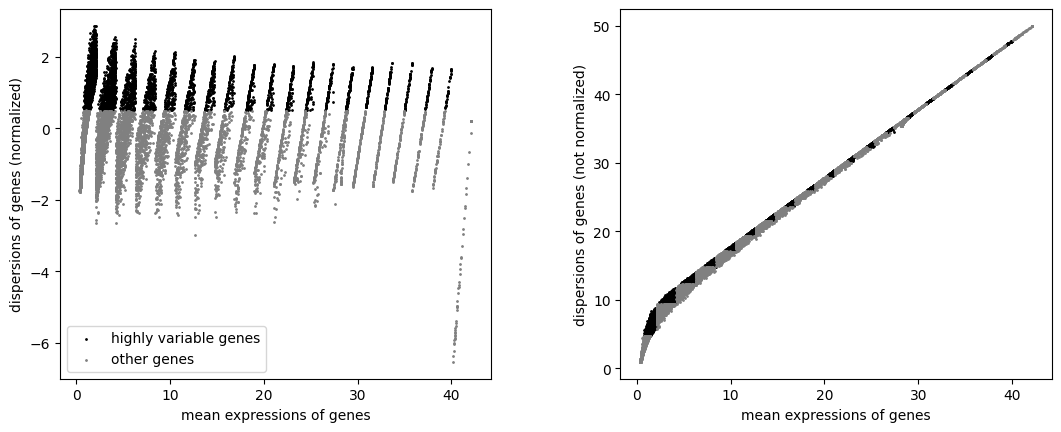

In [38]:
sc.pl.highly_variable_genes(tiss)

In [39]:
# Keep only HVGs
tiss = tiss[:, tiss.var.highly_variable]

tiss.var

,mean,std,highly_variable,means,dispersions,dispersions_norm
Xkr4,0.000748,0.018758,True,20.664540,28.406983,1.081782
Adhfe1,0.009195,0.088306,True,8.138965,14.913409,0.666577
Sgk3,0.065723,0.210407,True,1.968741,7.599824,2.188724
Cspp1,0.076726,0.221856,True,1.541900,5.769716,1.101240
Sulf1,0.066614,0.221105,True,1.973376,6.784622,1.704316
...,...,...,...,...,...,...
Arhgap6,0.068409,0.238531,True,1.677863,6.407495,1.480220
G530011O06Rik,0.045039,0.214648,True,4.014906,10.950014,1.859908
Spry3,0.001035,0.026449,True,23.033856,30.756092,1.376571
Kdm5d,0.030751,0.140348,True,5.502787,12.551003,0.792414


## Dimensionality Reduction
Through PCA

In [40]:
# PCA
sc.pp.pca(tiss)


computing PCA
    with n_comps=50
    finished (0:00:00)
    and added
    'X_pca', the PCA coordinates (adata.obs)
    'PCs', the loadings (adata.varm)
    'pca_variance', the variance / eigenvalues (adata.uns['pca'])
    'pca_variance_ratio', the variance ratio (adata.uns['pca'])


/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:384: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = x_pca


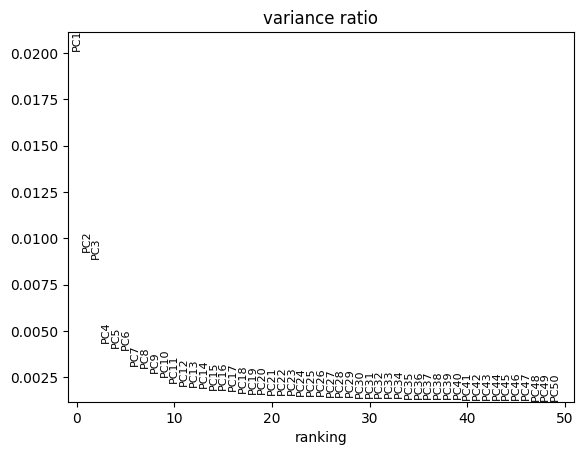

In [41]:
sc.pl.pca_variance_ratio(tiss, n_pcs=50)

## reading in annotations


In [42]:
bladder_annotations = pd.read_csv("../annotations/Bladder_droplet_annotation.csv")

y = bladder_annotations["cell_ontology_class"].values
y

array(['bladder cell', 'bladder cell', 'bladder cell', ...,
       'bladder cell', 'bladder urothelial cell',
       'bladder urothelial cell'], shape=(2500,), dtype=object)

In [43]:
tiss.obs["cell_ontology_class"] = y
tiss.obs

,n_genes,n_counts,cell_ontology_class
AAAGTAGAGATGCCAG-1,2853,10291.0,bladder cell
AACCGCGTCCAACCAA-1,4194,17520.0,bladder cell
AACTCCCGTCGGGTCT-1,3347,12944.0,bladder cell
AACTCTTAGTTGCAGG-1,3851,19594.0,bladder urothelial cell
AACTCTTTCATAACCG-1,3809,14594.0,bladder cell
...,...,...,...
TTGTAGGTCATGTAGC-1,4296,22993.0,bladder urothelial cell
TTTACTGGTGTTGAGG-1,3005,8753.0,bladder cell
TTTCCTCCATACCATG-1,3778,14665.0,bladder cell
TTTGTCAGTTACCGAT-1,4786,30363.0,bladder urothelial cell


## Clustering


In [44]:
# Compute t-SNE
sc.pp.neighbors(tiss, n_neighbors=15, n_pcs=10)

# below to mimic organ vignette supplementary preprocessing steps (using R, Seurat for FindClusters)
sc.tl.louvain(tiss, resolution=0.4) 

computing neighbors
    computing neighbors
    using 'X_pca' with n_pcs = 10
    computed neighbors (0:00:00)
    computed connectivities (0:00:00)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running Louvain clustering
    using the "louvain" package of Traag (2017)
    finished: found 8 clusters and added
    'louvain', the cluster labels (adata.obs, categorical) (0:00:00)


In [45]:
#inspection based on above ouptput
tiss.obs

,n_genes,n_counts,cell_ontology_class,louvain
AAAGTAGAGATGCCAG-1,2853,10291.0,bladder cell,2
AACCGCGTCCAACCAA-1,4194,17520.0,bladder cell,5
AACTCCCGTCGGGTCT-1,3347,12944.0,bladder cell,5
AACTCTTAGTTGCAGG-1,3851,19594.0,bladder urothelial cell,3
AACTCTTTCATAACCG-1,3809,14594.0,bladder cell,5
...,...,...,...,...
TTGTAGGTCATGTAGC-1,4296,22993.0,bladder urothelial cell,4
TTTACTGGTGTTGAGG-1,3005,8753.0,bladder cell,5
TTTCCTCCATACCATG-1,3778,14665.0,bladder cell,5
TTTGTCAGTTACCGAT-1,4786,30363.0,bladder urothelial cell,4


## Visualizing Clusters Using tSNE

computing tSNE
    using 'X_pca' with n_pcs = 10
    using sklearn.manifold.TSNE
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 2500 samples in 0.002s...
[t-SNE] Computed neighbors for 2500 samples in 0.057s...
[t-SNE] Computed conditional probabilities for sample 1000 / 2500
[t-SNE] Computed conditional probabilities for sample 2000 / 2500
[t-SNE] Computed conditional probabilities for sample 2500 / 2500
[t-SNE] Mean sigma: 1.502992
[t-SNE] KL divergence after 250 iterations with early exaggeration: 70.742661
[t-SNE] KL divergence after 1000 iterations: 0.874101
    finished: added
    'X_tsne', tSNE coordinates (adata.obsm)
    'tsne', tSNE parameters (adata.uns) (0:00:03)


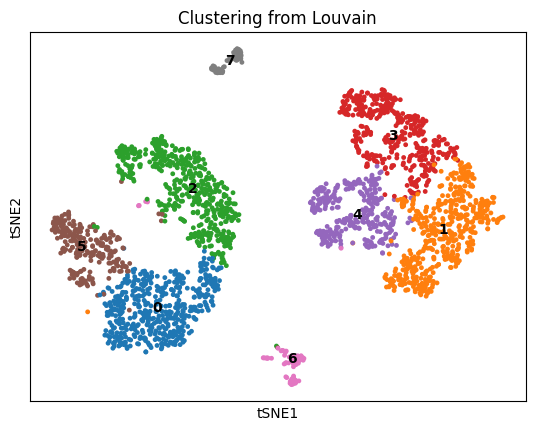

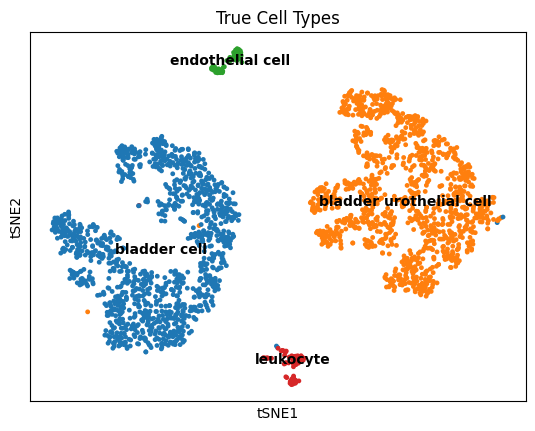

In [46]:
#computer tSNE
sc.tl.tsne(tiss, n_pcs=10, perplexity=30, random_state=0)

# Plot tSNE
sc.pl.tsne(tiss, color="louvain", title="Clustering from Louvain", legend_loc='on data')

# Plot tSNE
sc.pl.tsne(tiss, color="cell_ontology_class", title="True Cell Types", legend_loc='on data')


## Machine Learning related preprocessing

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler


# Encode labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Train-test split
X_train, X_test, Y_train, Y_test = train_test_split(
    tiss.X, y_encoded, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((2000, 5168), (500, 5168), (2000,), (500,))

## scikit-learn Machine Learning Classifiers

In [48]:
# --- CLASSIFIERS ---
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# optional xgboost support
try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False

In [49]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM (RBF Kernel)": SVC(probability=True),
    "Random Forest": RandomForestClassifier(n_estimators=200),
    "Gradient Boosting": GradientBoostingClassifier(),
    "KNN (k=5)": KNeighborsClassifier(),
    "Naive Bayes": GaussianNB()
}

In [50]:
from sklearn.metrics import classification_report, accuracy_score

# Train + evaluate each model
for name, model in models.items():
    model.fit(X_train, Y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(Y_test, preds)

    print("=" * 60)
    print(f"📌 Model: {name}")
    print(f"✅ Accuracy: {acc:.4f}")
    print("\nClassification Report:")
    print(classification_report(Y_test, preds))

📌 Model: Logistic Regression
✅ Accuracy: 0.9980

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       234
           1       1.00      1.00      1.00       238
           2       1.00      1.00      1.00        13
           3       1.00      1.00      1.00        15

    accuracy                           1.00       500
   macro avg       1.00      1.00      1.00       500
weighted avg       1.00      1.00      1.00       500

📌 Model: SVM (RBF Kernel)
✅ Accuracy: 0.9800

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98       234
           1       1.00      0.99      1.00       238
           2       0.89      0.62      0.73        13
           3       1.00      0.80      0.89        15

    accuracy                           0.98       500
   macro avg       0.96      0.85      0.90       500
weighted avg       0.98      0.98      0.98 

/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/naveenkumanan/miniconda3/envs/myenv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

## Pytorch Neural Network

In [51]:
import torch
from torch.utils.data import Dataset, DataLoader

# Normalize and scale
# scaler = StandardScaler(with_mean=False)
# X_scaled = scaler.fit_transform(X)
# commented out because data is already normalized and scaled using scanpy

# Convert to torch tensors
# train
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(Y_train, dtype=torch.long)
# test
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(Y_test, dtype=torch.long)



In [52]:
class SingleCellDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

dataset = SingleCellDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(dataset, batch_size=128, shuffle=True)


In [53]:
import torch.nn as nn
import torch.nn.functional as F

class Classifier(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, 10)
        self.fc2 = nn.Linear(10, 10)
        self.fc3 = nn.Linear(10, num_classes)
        # self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        # x = self.dropout(x)
        x = F.relu(self.fc2(x))
        # x = self.dropout(x)
        x = self.fc3(x)
        return x


In [54]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = Classifier(input_dim=X_train_tensor.shape[1], num_classes=len(le.classes_)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

for epoch in range(10):
    model.train()
    total_loss = 0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(train_loader):.4f}")


Epoch 1, Loss: 1.0679
Epoch 2, Loss: 0.4929
Epoch 3, Loss: 0.2711
Epoch 4, Loss: 0.1327
Epoch 5, Loss: 0.0754
Epoch 6, Loss: 0.0544
Epoch 7, Loss: 0.0449
Epoch 8, Loss: 0.0383
Epoch 9, Loss: 0.0341
Epoch 10, Loss: 0.0295


In [55]:
model.eval()
with torch.no_grad():
    y_test_pred = model(X_test_tensor.to(device)).argmax(dim=1).cpu().numpy()

acc = accuracy_score(Y_test, y_test_pred)

print("=" * 60)
print(f"📌 Model: Neural Network")
print(f"✅ Accuracy: {acc:.4f}")
print("\nClassification Report:")
print(classification_report(Y_test, y_test_pred))


📌 Model: Neural Network
✅ Accuracy: 0.9840

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       234
           1       0.97      1.00      0.98       238
           2       1.00      0.46      0.63        13
           3       1.00      1.00      1.00        15

    accuracy                           0.98       500
   macro avg       0.99      0.86      0.90       500
weighted avg       0.98      0.98      0.98       500



## Visualizing Model Results using TSNE

In [56]:

model.eval()
with torch.no_grad():
    preds = model(torch.tensor(tiss.X, dtype=torch.float32).to(device))
    tiss.obs["nn_pred"] = preds.argmax(1).cpu().numpy()


In [57]:
tiss.obs["nn_pred_label"] = le.inverse_transform(tiss.obs["nn_pred"])


In [58]:
import scanpy as sc

# Compute t-SNE
sc.pp.neighbors(tiss, n_neighbors=15, n_pcs=10)

# below to mimic organ vignette supplementary preprocessing steps (using R, Seurat for FindClusters)
sc.tl.leiden(tiss, resolution=3.5) 


sc.tl.tsne(tiss, n_pcs=10, perplexity=30, random_state=0)



computing neighbors
        initialized `.distances` `.connectivities` 
    computing neighbors
    using 'X_pca' with n_pcs = 10
    computed neighbors (0:00:00)
    computed connectivities (0:00:00)
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:00)
running Leiden clustering
    finished: found 33 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:00)
computing tSNE
    using 'X_pca' with n_pcs = 10
    using sklearn.manifold.TSNE
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 2500 samples in 0.001s...
[t-SNE] Computed neighbors for 2500 samples in 0.052s...
[t-SNE] Computed conditional probabilities for sample 1000 / 2500
[t-SNE] Computed conditional probabilities for sample 2000 / 2500
[t-SNE] Computed conditional probabilities for sample 2500 / 2500
[t-SNE] Mean sigma: 1.502992
[t-SNE] KL divergence after 250 iteration

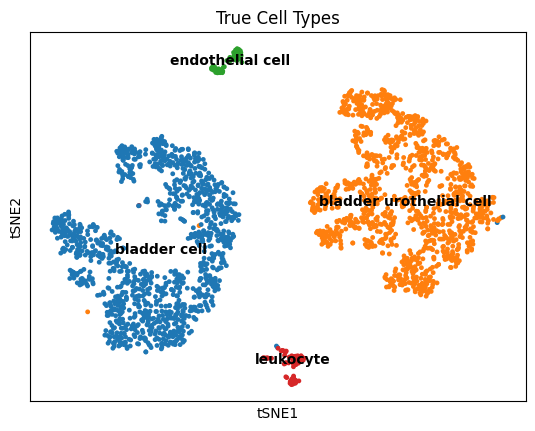

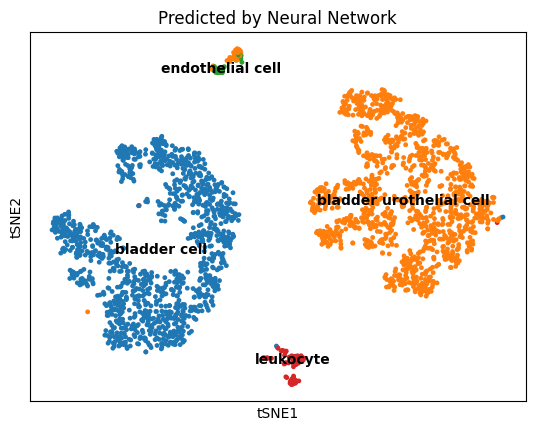

In [59]:
# True labels
sc.pl.tsne(tiss, color="cell_ontology_class", title="True Cell Types", legend_loc='on data')

# Predicted labels
sc.pl.tsne(tiss, color="nn_pred_label", title="Predicted by Neural Network", legend_loc='on data')


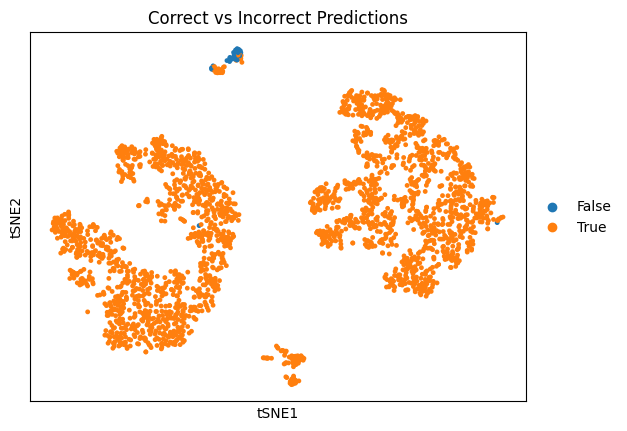

In [60]:
tiss.obs["correct"] = (tiss.obs["nn_pred_label"] == tiss.obs["cell_ontology_class"]).astype(str)
sc.pl.tsne(tiss, color="correct", title="Correct vs Incorrect Predictions")
